
**Curso: modelos de aprendizaje**

**UNIDAD 2**


---

*   NOMBRE: Luis Adán Castro Sánchez
*   NO CONTROL: 22111352



In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import os
DIR = "/content/drive/MyDrive/ITCJ/Semestre 9/IA/U2/Regresión Logística"
os.chdir(DIR)

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Librerías para preprocesamiento e ing de características
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder,StandardScaler, OrdinalEncoder,FunctionTransformer

# Librerías para la canalización
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.pipeline import make_pipeline

# Librerías para la regresión
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error, mean_squared_error, r2_score, confusion_matrix, precision_score,recall_score,accuracy_score
from sklearn.decomposition import PCA

from sklearn.preprocessing import PolynomialFeatures

---

## **<font color=" #895cf9">Explica brevemente el uso de las librerias del segmento de codigo anterior, haciendo uso de la siguiente tabla</font>**


| Library | Explanation  |
|----------|--------------|
|**import pandas as pd**| Permite trabajar con datos en tablas.	|
|**import numpy as np**| Sirve para calculos numéricos y arreglos multidimensionales.	|
|**import matplotlib.pyplot as plt**| Crear gráficas y visualizaciones. |
|**import seaborn as sns** | Sirve para la visualización estadística basada en matplotlib. |
|**from sklearn.impute import SimpleImputer ** | Rellenar valores faltantes en un dataset. |
|**from sklearn.preprocessing import MinMaxScaler** | Escala los datos para que estén entre 0 y 1. |
|**from sklearn.preprocessing import OneHotEncoder** | Convierte variables catergóricas en variables binarias. |
|**from sklearn.preprocessing import StandardScaler** | Estandariza los datos para que tengan media 0 y desviación estándar 1. |
|**from sklearn.preprocessing import OrdinalEncoder**| Convierte categorías en valores numéricos ordenados. |
|**from sklearn.preprocessing import FunctionTransformer** | Permite aplicar una función personalizada a los datos. |
|**from sklearn.compose import ColumnTransformer**| Permite aplicar diferentes transformaciones a distintas columnas del dataset. |
|**from sklearn.compose import make_column_selector**| Selecciona columnas automáticamente según su tipo. |
|**from sklearn.pipeline import make_pipeline**| Permite encadenar pasos de procesamiento y modelos en un solo flujo. |
|**from sklearn.linear_model import LinearRegression**| Modelo de regresión lineal para predecir valores continuos |
| **from sklearn.linear_model import LogisticRegression** | Modelo usado para clasificación.
| **from sklearn.metrics import mean_squared_error** | Mide el error cuadrático medio en modelos de regresión
| **from sklearn.metrics import r2_score** | Mide que tan bien explica el modelo la variabilidad de los datos
| **from sklearn.metrics import confusion_matrix** | Tabla que muestra aciertos y errores en un modelo de clasificación
| **from sklearn.metrics import precision_score** | Mide que proporcion de predicciones positivas fueron correctas
| **from sklearn.metrics import recall_score** | Mide que proporcion de positivos reales fue detectada por el modelo
| **from sklearn.metrics import accuracy_score** | Mide el porcentaje total de predicciones correctas
| **from sklearn.descomposition import PCA** | Reduce la cantidad de variables del dataset manteniendo la mayor información posible.
| **from sklearn.preprocessing import PolynomialFeatures** | Crea nuevas variables polinomiales







---

In [6]:
#lectura del .csv con pandas
data_df = pd.read_csv('data.csv')
data_df

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,...,25.380,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,...,24.990,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,...,23.570,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,...,14.910,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,...,22.540,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,926424,M,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,...,25.450,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115
565,926682,M,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,...,23.690,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637
566,926954,M,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,...,18.980,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820
567,927241,M,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,...,25.740,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400


# **Parte 1**. EDA

Haz que el `id` sea el índice del dataframe y efectúa una exploración inicial de los datos a través de:

In [7]:
#utilice funcion .set_index()
#Guarde los cambios con inplace=True

#-----------------------------------------------------
#Escriba su codigo
data_df.set_index('id',inplace=True)
#-----------------------------------------------------

#-----------------------------------------------------


In [8]:
data_df

,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
id,,,,,,,,,,,,,,,,,,,,,
842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,0.2419,...,25.380,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890
842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,0.1812,...,24.990,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902
84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,0.2069,...,23.570,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758
84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,0.2597,...,14.910,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300
84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,0.1809,...,22.540,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
926424,M,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,...,25.450,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115
926682,M,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,0.1752,...,23.690,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637
926954,M,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,...,18.980,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820




1a) Estadísticas descriptivas para todas las variables del dataframe.

In [9]:
#.describe para variables Numericas
#-----------------------------------------------------
data_df.describe().T
#-----------------------------------------------------

,count,mean,std,min,25%,50%,75%,max
radius_mean,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
texture_mean,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
perimeter_mean,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
area_mean,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
smoothness_mean,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
compactness_mean,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
concavity_mean,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
concave points_mean,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
symmetry_mean,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
fractal_dimension_mean,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744


In [10]:
#.describe() para variable categoricas
#-----------------------------------------------------
data_df.describe(include = "object").T
#-----------------------------------------------------

,count,unique,top,freq
diagnosis,569,2,B,357


1b) Valores únicos por variable para identificar posibles variables categóricas.

In [11]:
# Se hace una lista de variables numéricas y otra de categóricas.

#-----------------------------------------------------
num_cols = data_df.select_dtypes(include=np.number).columns.tolist() #para variables numericas
cat_cols = data_df.select_dtypes(exclude=np.number).columns.tolist() #para variables Categoricas
#-----------------------------------------------------

In [12]:
# Recuento de cada categoría única en las variables categóricas
for column in cat_cols:
    print(column)
    print(data_df[column].nunique())
    print('-' * 50)

diagnosis
2
--------------------------------------------------


In [13]:
# Recuento de cada categoría única en las variables categóricas
for column in cat_cols:
    print(column)
    print(data_df[column].value_counts())
    print('-' * 50)

diagnosis
diagnosis
B    357
M    212
Name: count, dtype: int64
--------------------------------------------------


1c) Búsqueda de valores faltantes.

In [14]:
#Explica cada linea de codigo
print('Número valores faltantes: ')
for col in data_df.columns:
  valor=sum(data_df[col].isna())
  porcentaje=data_df[col].isna().mean()*100
  print('{}:{}: porcentaje :{}'.format(col,valor,porcentaje))

Número valores faltantes: 
diagnosis:0: porcentaje :0.0
radius_mean:0: porcentaje :0.0
texture_mean:0: porcentaje :0.0
perimeter_mean:0: porcentaje :0.0
area_mean:0: porcentaje :0.0
smoothness_mean:0: porcentaje :0.0
compactness_mean:0: porcentaje :0.0
concavity_mean:0: porcentaje :0.0
concave points_mean:0: porcentaje :0.0
symmetry_mean:0: porcentaje :0.0
fractal_dimension_mean:0: porcentaje :0.0
radius_se:0: porcentaje :0.0
texture_se:0: porcentaje :0.0
perimeter_se:0: porcentaje :0.0
area_se:0: porcentaje :0.0
smoothness_se:0: porcentaje :0.0
compactness_se:0: porcentaje :0.0
concavity_se:0: porcentaje :0.0
concave points_se:0: porcentaje :0.0
symmetry_se:0: porcentaje :0.0
fractal_dimension_se:0: porcentaje :0.0
radius_worst:0: porcentaje :0.0
texture_worst:0: porcentaje :0.0
perimeter_worst:0: porcentaje :0.0
area_worst:0: porcentaje :0.0
smoothness_worst:0: porcentaje :0.0
compactness_worst:0: porcentaje :0.0
concavity_worst:0: porcentaje :0.0
concave points_worst:0: porcentaje :

1d) Diagrama de barras para determinar la frecuencia de los diagnósticos (cantidad de observaciones con resultado benigno y maligno)

<Axes: xlabel='diagnosis', ylabel='count'>

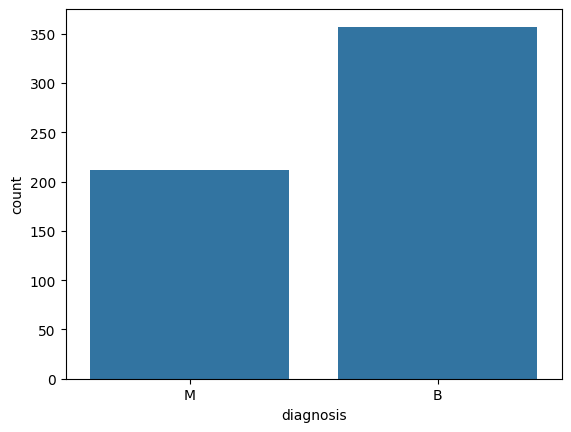

In [15]:
#utilice sns.countplot()
#-----------------------------------------------------
sns.countplot(data=data_df, x='diagnosis')
#-----------------------------------------------------

2. Como hay tres valores relacionados con la misma característica (`mean`, `se` y `worst`) es muy probable que exista multicolinealidad en el conjunto.

La multicolinealidad en regresión es una condición que ocurre cuando algunas variables predictoras están fuertemente correlacionadas entre sí, de tal manera que si se incluyen simultáneamente en un modelo, impiden explicar de manera correcta el efecto que cada una tiene sobre la variable respuesta. Existen muchas formas de analizar si hay colinealidad en los modelos, una de ellas es el alto coeficiente de correlación entre variables.

Para observar este efecto, elabora un mapa de calor que cuantifique la correlación de las variables numéricas en el dataframe.

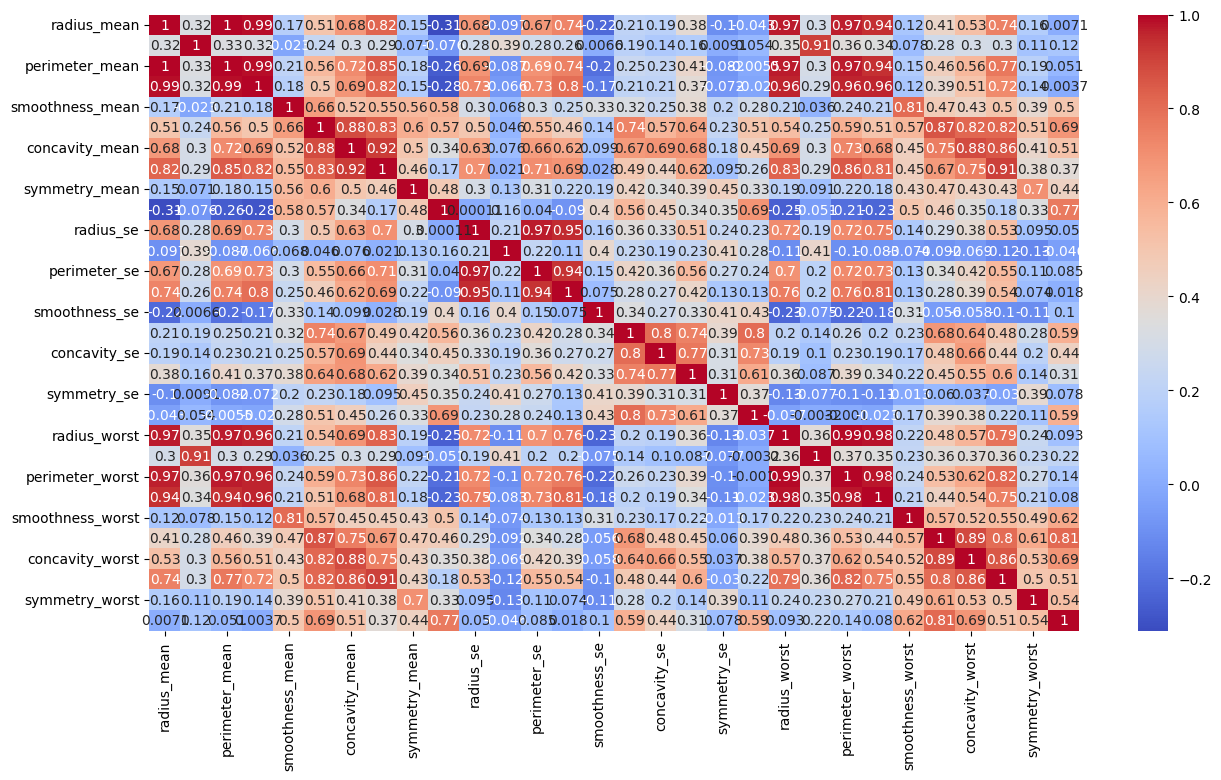

In [16]:
numeric_df = data_df.select_dtypes(include=[float, int])

#-----------------------------------------------------
correlation = numeric_df.corr(method="pearson")
sns.heatmap(correlation, annot=True, cmap="coolwarm")#complete esta linea de codigo para graficas el mapa de calor
plt.gcf().set_size_inches(15, 8)
#-----------------------------------------------------

Si te fijas en los valores de correlación entre las variables `_mean` y `_worst` es evidente la multicolinearidad.

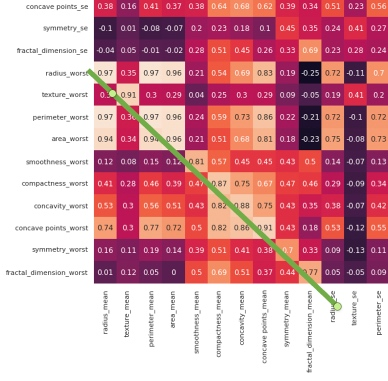

Por ejemplo, la columna `radius_mean` tiene una correlación de 0.97 con la columna `radius_worst`. Esto es algo inevitable, porque las columnas "peores" son esencialmente solo un subconjunto de las columnas "medias".

Para solucionar el problema numérico de la multicolinealidad, tradicionalmente se recurre a eliminar variables o efectuar análisis de componentes principales (PCA) con las `X`’s y usar los componentes como variables independientes en un modelo final.

Conduciremos esta actividad en esos dos sentidos.


# **Parte 2**. Modelo con eliminación de variables altamente correlacionadas  

Elimina las variables altamente correlacionadas:

3a) Ahora que sabes que las variables `_mean` y `_worst` tienen correlación alta, hay que quitar del dataframe un conjunto. Borra las columnas `_worst`.

In [17]:
#-----------------------------------------------------
#Elimine TODAS las columnas _worst
columnas_a_eliminar=['radius_worst','texture_worst']
#-----------------------------------------------------

#para borrar las columnas _worst
new_data_df = data_df.drop(columnas_a_eliminar, axis=1)

#-----------------------------------------------------
#Convierte new_data_df en Dataframe usando .DataFrame() de la libreria de pandas
nuevo_df= pd.DataFrame(new_data_df)#completa codigo
nuevo_df
#-----------------------------------------------------

,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,symmetry_se,fractal_dimension_se,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
id,,,,,,,,,,,,,,,,,,,,,
842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,0.2419,...,0.03003,0.006193,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890
842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,0.1812,...,0.01389,0.003532,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902
84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,0.2069,...,0.02250,0.004571,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758
84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,0.2597,...,0.05963,0.009208,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300
84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,0.1809,...,0.01756,0.005115,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
926424,M,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,...,0.01114,0.004239,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115
926682,M,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,0.1752,...,0.01898,0.002498,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637
926954,M,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,...,0.01318,0.003892,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820


En las graficas de dispersion, los patrones lineales en los diagramas de dispersion se refieren a la relacion entre dos variables que sigue una tendencia aproximadamente en linea recta, ya sea en direccion ascendente o descentende

* **Patron lineal positivo**: Si la linea se inclina hacia arriba (de izquierda a derecha), indica que hay una relacion directa entre las variables: cuando la variable aumenta, la otra tambien lo hace, es decir, CORRELACION POSITIVA

* **Patron lineal negativo**: si la linea se incluna hacia abajo (de izquierda a derecha), indica quue cuando una variable aumenta, la otra disminuye, es decir, CORRELACION NEGATIVA

* **Patron lineal perfecto**, si los puntos siguen una linea recta perfecta, la relacion entre las variables es exactamente lineal, sin desviaciones.


3b. Entre las variables `_mean`, identifica patrones lineales con diagramas de dispersión usando:

    sns.pairplot(data=nuevo_df[['radius_mean',
        'texture_mean',
        'perimeter_mean',
        'area_mean',
        'smoothness_mean',
        'compactness_mean',
        'concavity_mean',
        'concave points_mean',
        'symmetry_mean',
        'fractal_dimension_mean']])



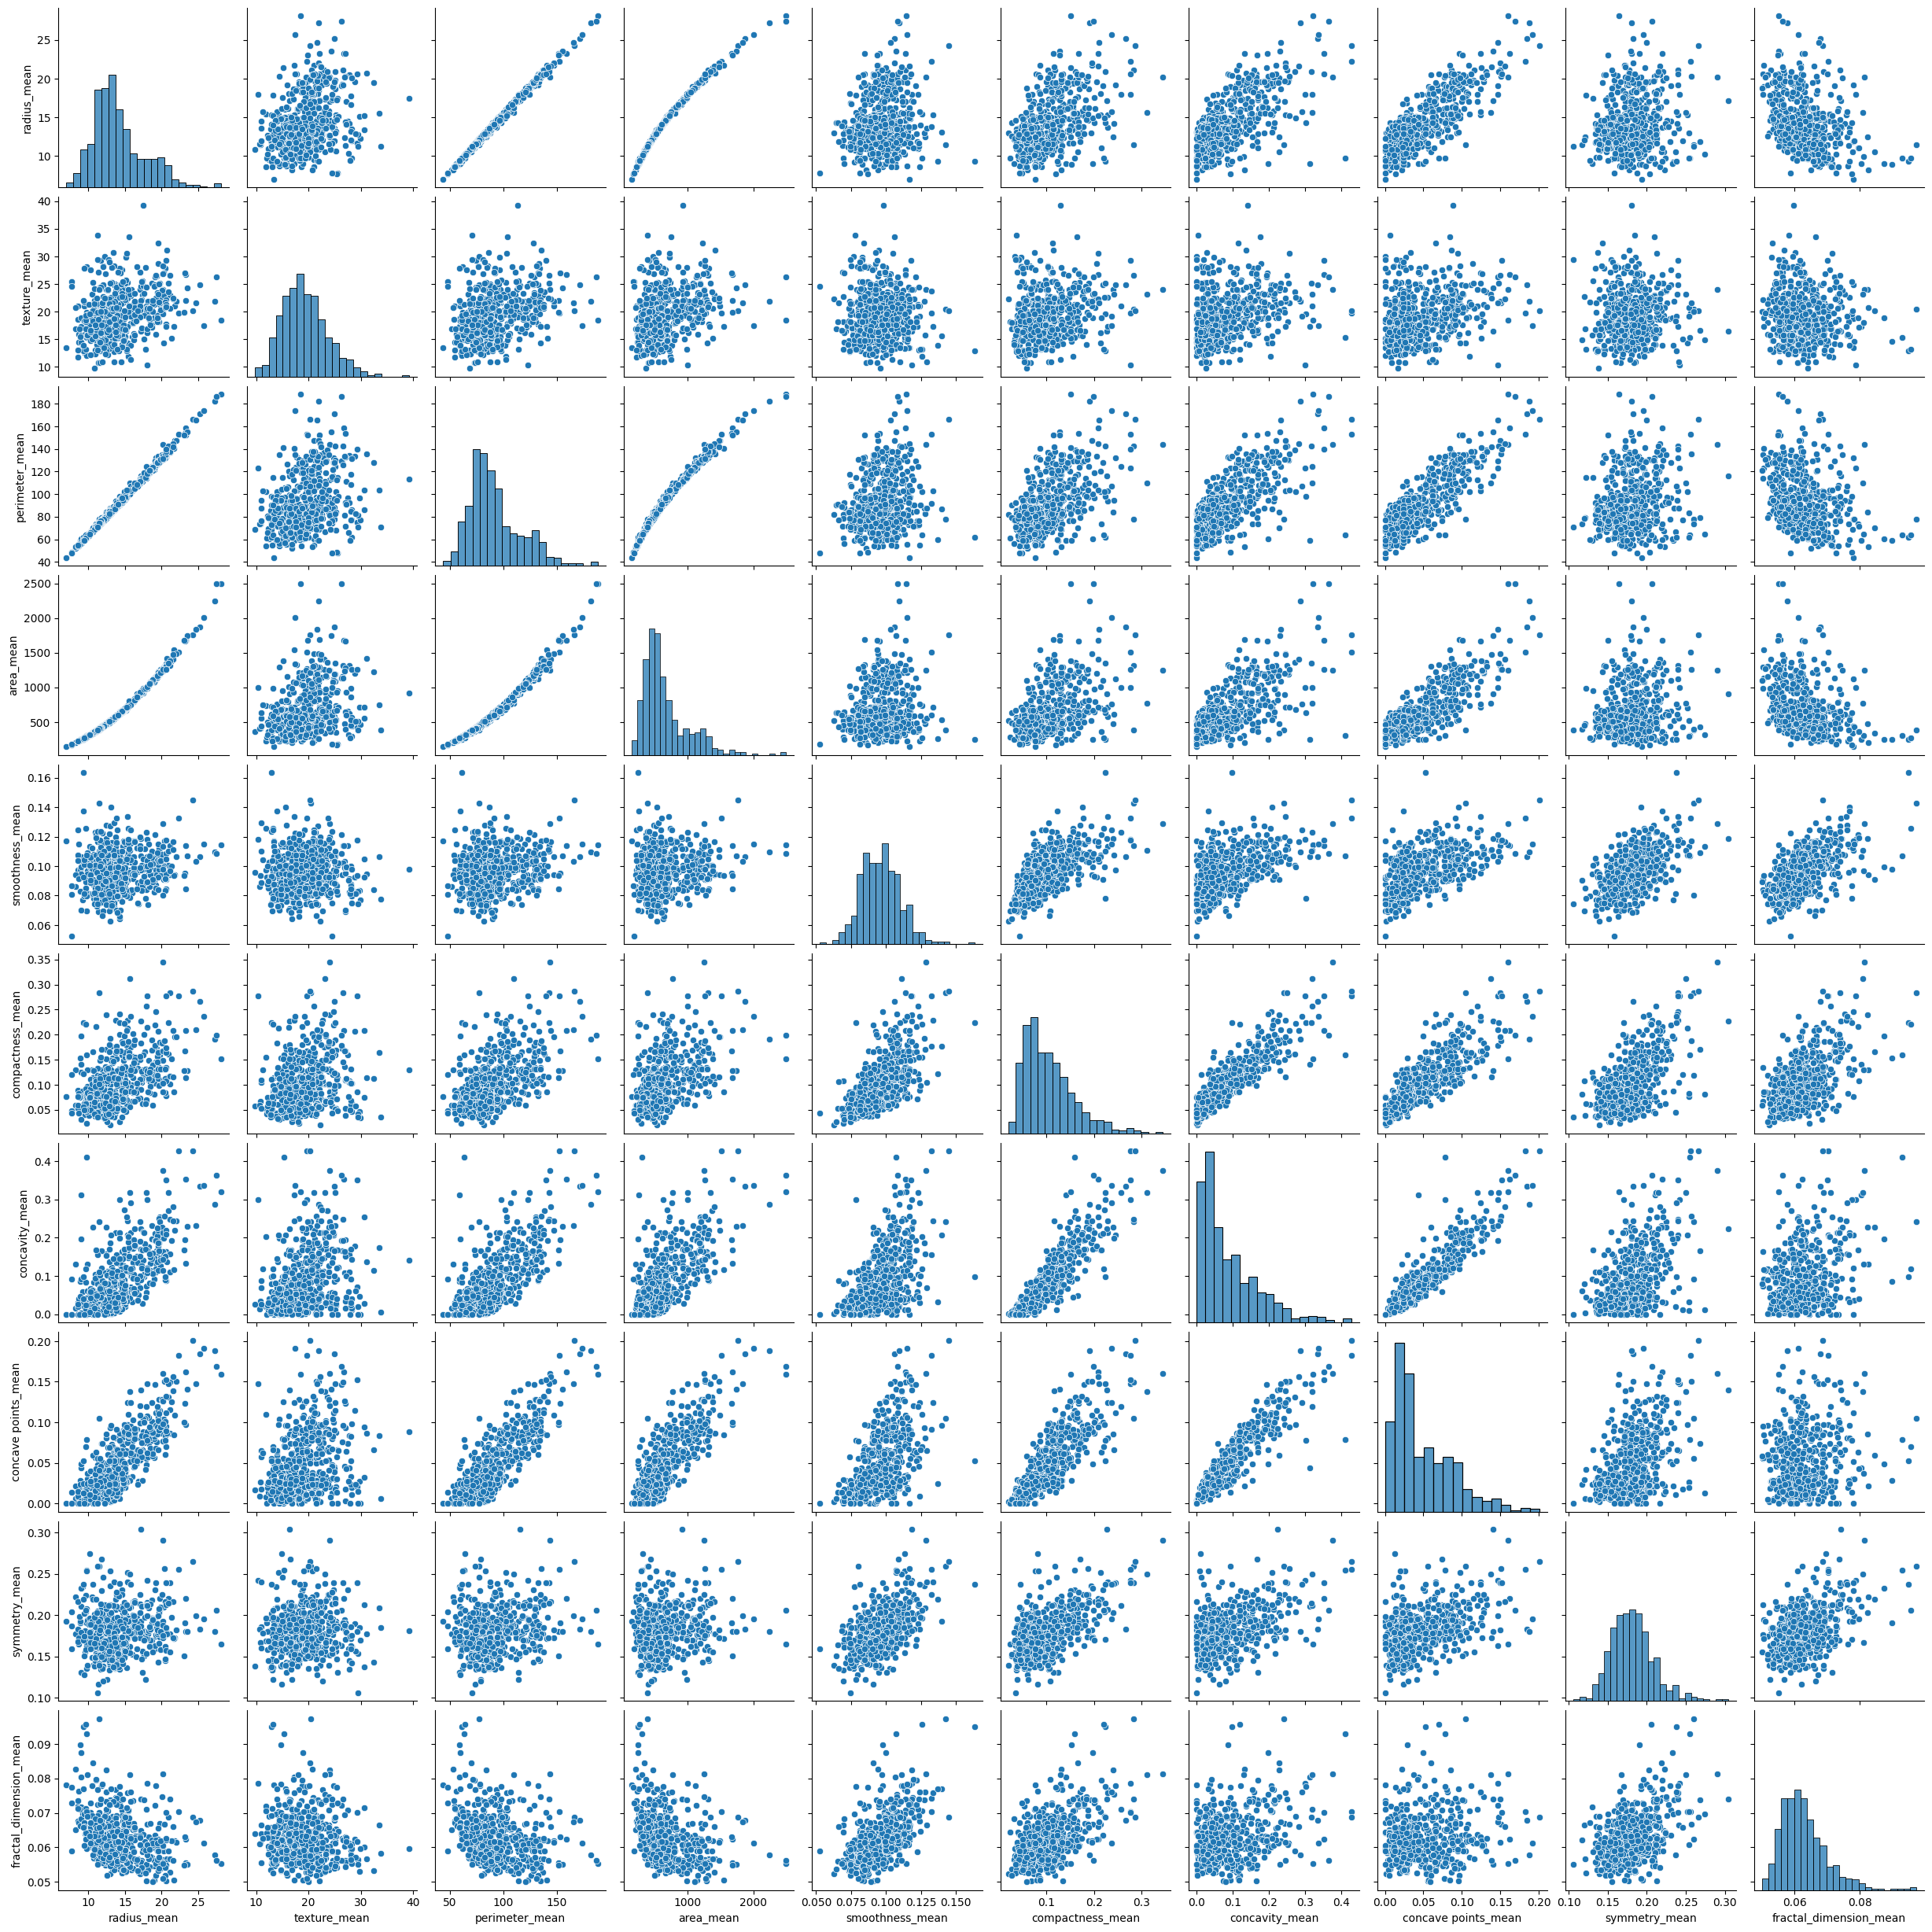

In [18]:
#-----------------------------------------------------
#Pega aqui el codigo sns.pairplot()
sns.pairplot(data=nuevo_df[['radius_mean',
    'texture_mean',
    'perimeter_mean',
    'area_mean',
    'smoothness_mean',
    'compactness_mean',
    'concavity_mean',
    'concave points_mean',
    'symmetry_mean',
    'fractal_dimension_mean']])
#-----------------------------------------------------

De la matriz podrás observar relaciones lineales bastante evidentes entre:


*   `radius_mean`, `perimeter_mean` y `area_mean`
*   `compactness_mean`, `concavity_mean`, `concave_points_mean`

Sabemos que el perímetro y el área de un círculo, se calculan a partir del radio. Entonces, la relación entre las primeras tres variables es muy clara para nosotros.

3c) Elabora otro mapa de calor confirmar con los valores de correlación.


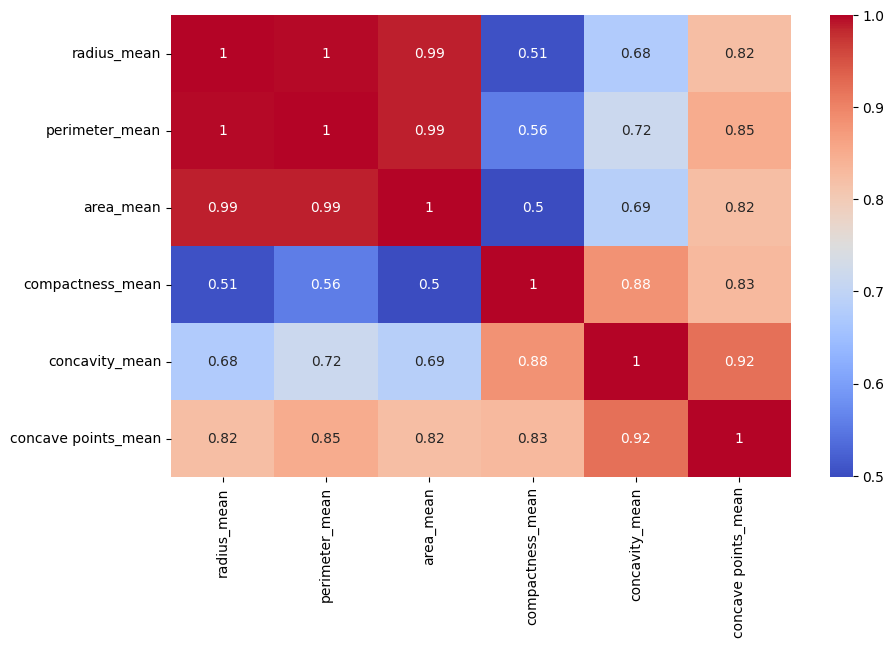

In [19]:
#-----------------------------------------------------
#Agrega codigo para el mapa de calor
variables = data_df[['radius_mean', 'perimeter_mean', 'area_mean',
                     'compactness_mean', 'concavity_mean', 'concave points_mean']]

correlation = variables.corr(method="pearson")

sns.heatmap(correlation, annot=True, cmap="coolwarm")
plt.gcf().set_size_inches(10,6)
plt.show()
#-----------------------------------------------------

3d) Después de observar los valores, nos quedaremos con sólo una variable de cada trío: `radius_mean` y `compactness_mean`. Elimina las restantes, no sólo del conjunto `_mean`, sino también de `_se`.

In [20]:

#-----------------------------------------------------
#escriba TODAS las columnas que seran eliminadas
columnas_a_eliminar = [
    'perimeter_mean',
    'area_mean',
    'concavity_mean',
    'concave points_mean',
    'perimeter_se',
    'area_se',
    'concavity_se',
    'concave points_se'
]
#-----------------------------------------------------

new_data_df = nuevo_df.drop(columnas_a_eliminar, axis=1)


#-----------------------------------------------------
#Convierte new_data_df en Dataframe usando .DataFrame() de la libreria de pandas
new_data_df = pd.DataFrame(new_data_df)

new_data_df
#-----------------------------------------------------


,diagnosis,radius_mean,texture_mean,smoothness_mean,compactness_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,smoothness_se,...,symmetry_se,fractal_dimension_se,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
id,,,,,,,,,,,,,,,,,,,,,
842302,M,17.99,10.38,0.11840,0.27760,0.2419,0.07871,1.0950,0.9053,0.006399,...,0.03003,0.006193,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890
842517,M,20.57,17.77,0.08474,0.07864,0.1812,0.05667,0.5435,0.7339,0.005225,...,0.01389,0.003532,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902
84300903,M,19.69,21.25,0.10960,0.15990,0.2069,0.05999,0.7456,0.7869,0.006150,...,0.02250,0.004571,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758
84348301,M,11.42,20.38,0.14250,0.28390,0.2597,0.09744,0.4956,1.1560,0.009110,...,0.05963,0.009208,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300
84358402,M,20.29,14.34,0.10030,0.13280,0.1809,0.05883,0.7572,0.7813,0.011490,...,0.01756,0.005115,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
926424,M,21.56,22.39,0.11100,0.11590,0.1726,0.05623,1.1760,1.2560,0.010300,...,0.01114,0.004239,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115
926682,M,20.13,28.25,0.09780,0.10340,0.1752,0.05533,0.7655,2.4630,0.005769,...,0.01898,0.002498,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637
926954,M,16.60,28.08,0.08455,0.10230,0.1590,0.05648,0.4564,1.0750,0.005903,...,0.01318,0.003892,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820


Observa la distribución de las variables resultantes (deben ser 12, sin contar la columna de indice):

4a) Utilizando histogramas. Guarda en una variable (`skew_cols`) las que tengan marcado sesgo positivo. Para dar seguridad a tu selección, elige aquellas cuyo resultado de aplicar la función `skew()` sea mayor a 1.

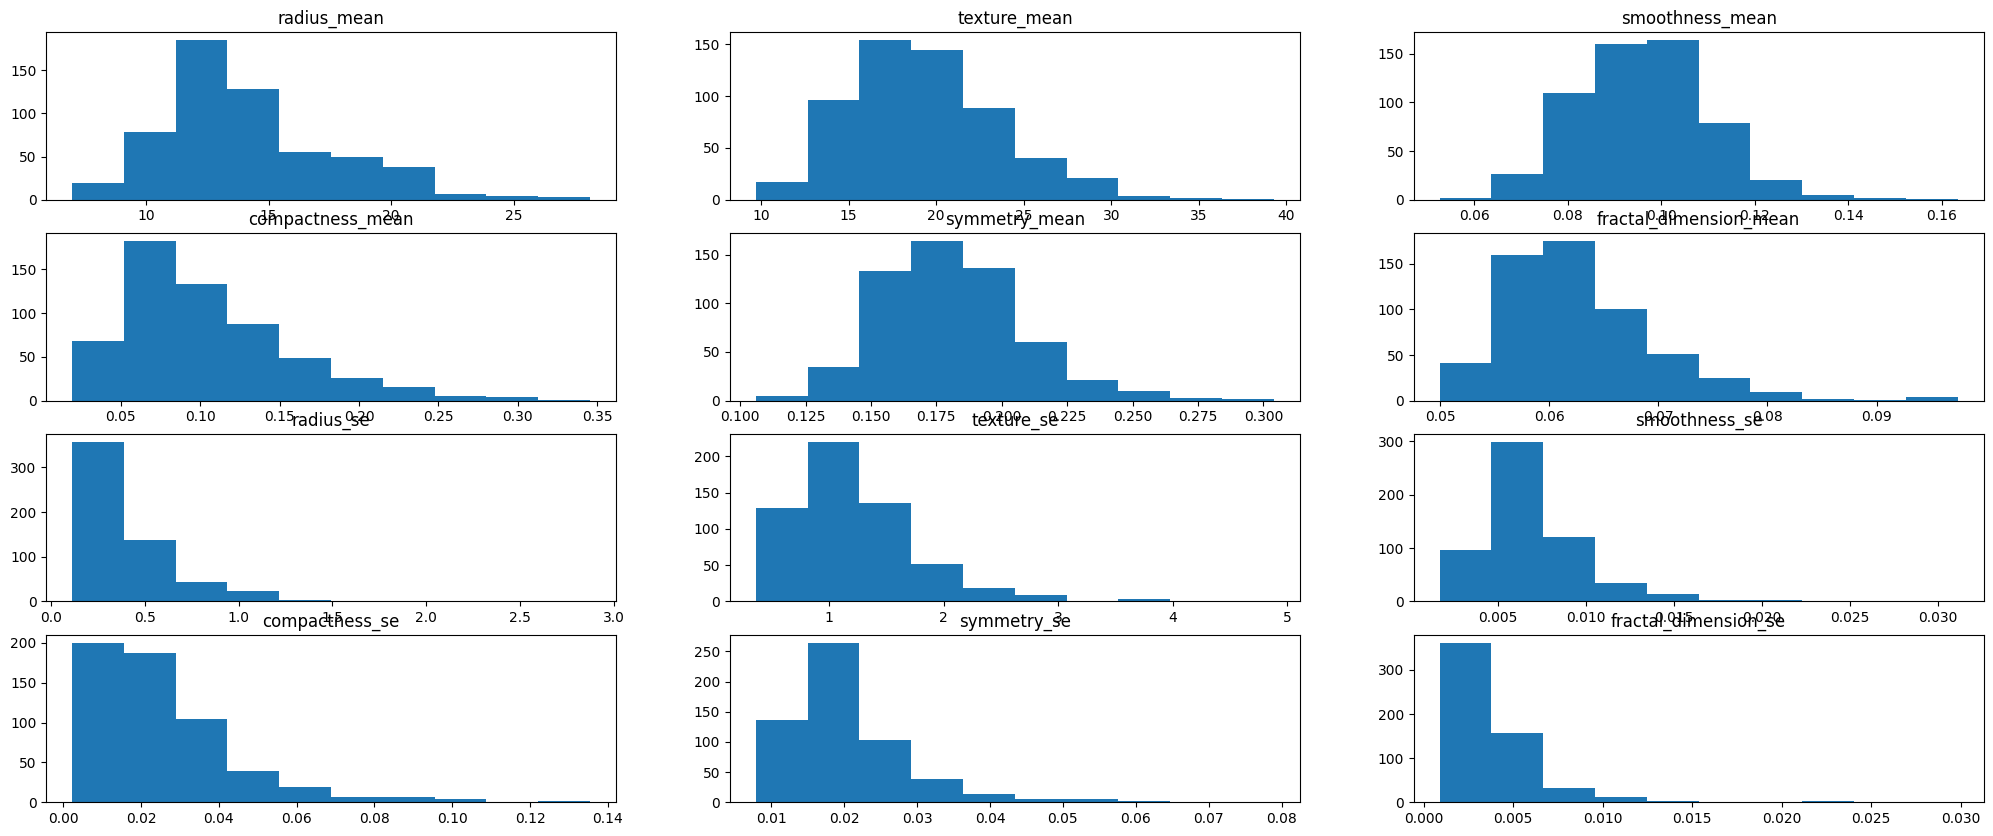

In [21]:
skew_cols_df = pd.DataFrame() # Crea un DataFrame vacío donde se guardarán las columnas con alta asimetría
fig, axes = plt.subplots(4, 3, figsize=(25,10)) # Crea una figura con múltiples subgráficas
axes = axes.ravel() # Convierte la matriz de ejes en un arreglo de una sola dimensión
num_cols = new_data_df.select_dtypes(include=np.number).columns.tolist()# Obteniene los nombres de todas las columnas numéricas del DataFrame

for col, ax in zip(num_cols, axes): # Recorre simultáneamente las columnas numéricas y los espacios de gráficas
    ax.hist(new_data_df[col]) # Crea un histograma con los valores de la columna actual
    ax.set(title=f'{col}', xlabel=None) # Asigna como título el nombre de la columna

    if new_data_df[col].skew() > 1: # Calcula la asimetría de la columna
        skew_cols_df[col] = new_data_df[col] # Guarda la columna sesgada dentro del DataFrame creado al inicio

skew_cols = skew_cols_df.columns.values# Obtiene los nombres de las columnas que presentaron alta asimetría

In [22]:
skew_cols

array(['compactness_mean', 'fractal_dimension_mean', 'radius_se',
       'texture_se', 'smoothness_se', 'compactness_se', 'symmetry_se',
       'fractal_dimension_se'], dtype=object)

4b) Dibujando box plots de todas las variables. Guarda en una variable (`scale_cols`) aquellas que no se encuentren en el intervalo [0,1]


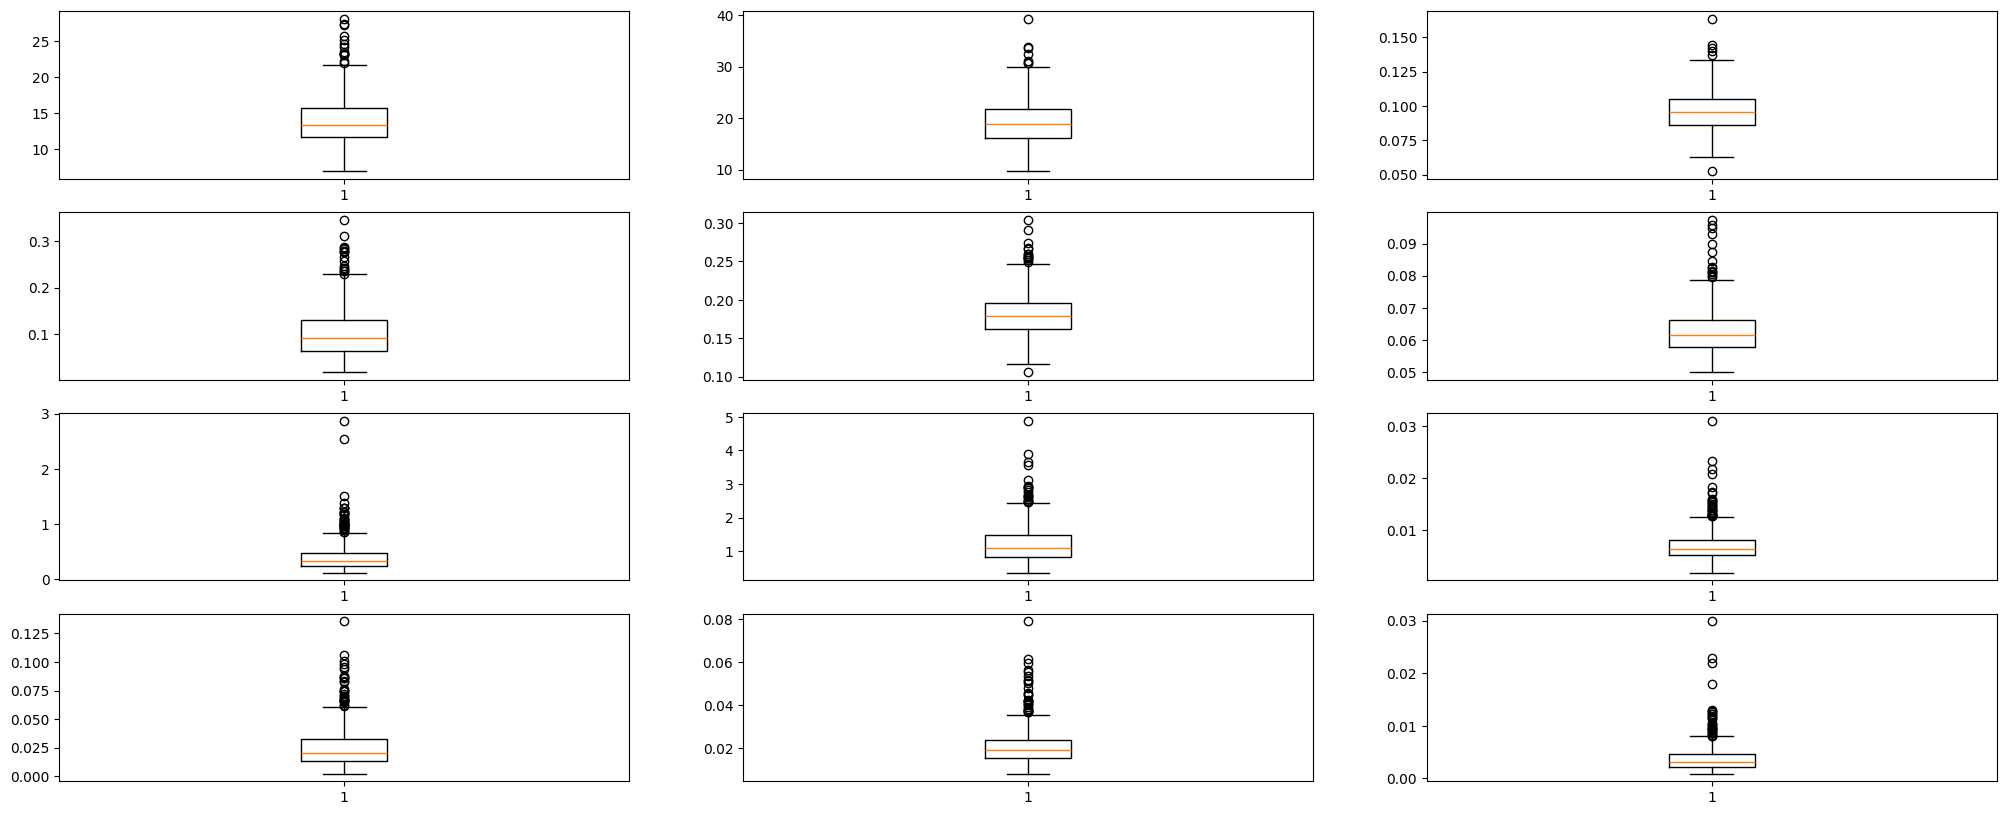

In [23]:
scale_cols_df = pd.DataFrame()
fig, axes = plt.subplots(4,3, figsize=(25,10))
axes = axes.ravel()

#-----------------------------------------------------
for col, ax in zip(new_data_df[num_cols], axes):

  ax.boxplot(new_data_df[col])

  if new_data_df[col].max() > 1 or new_data_df[col].min() < 0:
      scale_cols_df[col] = new_data_df[col]
#-----------------------------------------------------

scale_cols = scale_cols_df.columns.values

In [24]:
scale_cols

array(['radius_mean', 'texture_mean', 'radius_se', 'texture_se'],
      dtype=object)

Con todo el análisis anterior, estamos listos para generar un modelo *baseline* denominado `logr_model`. Para ello:

5a) Vuelve a leer el contenido del archivo, haz que el `id` sea el índice y separa las variables del dataframe: en `X` coloca los predictores y en `y` la variable de respuesta o salida (`diagnosis`). Divide el conjunto en entrenamiento y prueba (80:20) considerando el parámetro `random_state` con el valor de 1.

In [25]:
data_df = pd.read_csv('data.csv')

#-----------------------------------------------------
#AGREGA LINEA DE CODIGO PARA CONVERTIR COLUMNA "ID" EN INDICE
data_df = data_df.set_index('id')
X = data_df.drop('diagnosis', axis=1)
y = data_df['diagnosis']

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=1
)
#-----------------------------------------------------

In [26]:
X = data_df.copy() #Se crea copia del df


#-----------------------------------------------------
#                                  COMPLETA CODIGO
# se elimina variable Categorica "diagnosis" de (X), debido a se sera utilizada como variable de salida (y)
#-----------------------------------------------------
#Especifique la columna que desea eliminar
#Utilice el parametro axis=1, permitira eliminar la columna
#Guarde los cambios agregando el parametro inplace=True

X.drop('diagnosis', axis=1, inplace=True) #Caracteristica / variable Entrada
#-----------------------------------------------------

#-----------------------------------------------------
y = data_df['diagnosis'] #Objetivo /Variable salida
#-----------------------------------------------------

In [27]:
#Libreria necesaria para realizar la particion del conjunto de datos

from sklearn.model_selection import train_test_split

# Se divide el conjunto en entrenamiento y prueba (80:20), es decir, 80% para Entrenamiento (train) y 20% para Prueba (test)


5b) Prepara un transformador, denominado `preprocessing`, para borrar las columnas altamente correlacionadas (las 18 variables que se determinaron en los ejercicios previos) Asegúrate de incluir el parámetro `remainder='passthrough'` para mantener el resto de las variables.

In [28]:
# Se crea una lista con los nombres de todas las columnas que se desean eliminar del dataset
columnas_a_eliminar = ['radius_worst','texture_worst','perimeter_worst','area_worst','smoothness_worst','compactness_worst','concavity_worst','concave points_worst','symmetry_worst','fractal_dimension_worst','perimeter_mean','area_mean','concavity_mean','concave points_mean','perimeter_se','area_se','concavity_se','concave points_se']

# ColumnTransformer es una herramienta de scikit-learn que permite aplicar diferentes transformaciones a distintas columnas
preprocessing = ColumnTransformer(

    # Se define una lista de transformaciones a aplicar
    [
        #drop indica que las columnas especificadas serán eliminadas, columnas_a_eliminar son la lista de columnas que se eliminarán
        ('num', 'drop', columnas_a_eliminar)
    ],

    # remainder='passthrough' indica que todas las columnas que NO estén en la lista de columnas a eliminar se mantendrán sin modificación
    remainder='passthrough'
)

5c) Entrena el modelo `logr_model` con el transformador `preprocessing` y  regresión logística.

Como la salida `y` está en términos de las etiquetas `'B'` y `'M'`, en lugar de 0 y 1, para evaluar el modelo en el conjunto de prueba deberás especificar la clase positiva. En el caso de la matriz de confusión, indica el orden de las etiquetas con `labels=['B','M']`, porque `'B'` es la clase negativa (ésta se especifica primero) y `'M'` la positiva. Para las métricas de *recall* y *precision*, utiliza el parámetro `pos_label='M'`. Como *accuracy* ocupa la suma de ambas clases y el total de las observaciones, no requiere ninguna especificación. Si quisieras omitir estos parámetros, tendrías que sustituir `'B'` por 0 y `'M'` por 1, previo a la construcción del modelo.

In [29]:
# Se crea el modelo utilizando un pipeline
logr_model = make_pipeline(preprocessing, LogisticRegression())

# Se entrena el modelo usando los datos de entrenamiento, X_train contiene las variables predictoras, y y_train contiene la variable objetivo
logr_model.fit(X_train, y_train)

# Se generan las predicciones usando los datos de prueba
predictions = logr_model.predict(X_test)

# Se imprime la matriz de confusión
print('matriz de confusion:\n', confusion_matrix(y_test, predictions, labels=['B','M']))

# Mide qué proporción de los casos malignos reales fueron correctamente detectados por el modelo
print('recall    :\t', recall_score(y_test, predictions, pos_label='M'))

# Mide qué proporción de los casos que el modelo predijo como malignos, realmente lo eran
print('precision :\t', precision_score(y_test, predictions, pos_label='M'))

# Mide el porcentaje total de predicciones correctas considerando ambas clases.
print('accuracy  :\t', accuracy_score(y_test, predictions))

matriz de confusion:
 [[68  4]
 [10 32]]
recall    :	 0.7619047619047619
precision :	 0.8888888888888888
accuracy  :	 0.8771929824561403


<font color=" ORANGE">INTERPRETE LOS RESULTADOS OBTENIDOS EN MATRIZ DE CONFUSION Y METRICAS

El modelo de regresión logística presenta un buen desempeño general con una exactitud del 87.7%. Además, la precisión es alta (88.9%), lo que indica que cuando el modelo predice un tumor maligno, generalmente es correcto.

Sin embargo, el recall es menor (76.2%), lo que significa que algunos tumores malignos no son detectados y se clasifican como benignos. En aplicaciones médicas esto es importante, ya que los falsos negativos (10 casos) pueden representar diagnósticos incorrectos que retrasen el tratamiento.

Para generar un modelo `logr_model2` con transformación y escalamiento:

6a) Modifica el transformador anterior para, además del borrado de las columnas correlacionadas, aplicar la raíz cuadrada a los predictores con sesgo (previamente almacenados en `skew_cols`) y escalamiento *MinMax* a los predictores con escala mayor a 1 (previamente almacenados en `scale_cols`) Como no todos los predictores serán eliminados o transformados, asegúrate de incluir el parámetro `remainder='passthrough'`

In [30]:
# Se crea un nuevo transformador de columnas usando ColumnTransformer
preprocessing2 = ColumnTransformer([
    # num0 es el nombre asignado a esta transformación
    # drop indica que las columnas especificadas serán eliminadas del dataset
    # columnas_a_eliminar es lista de columnas previamente definidas que se consideran redundantes o altamente correlacionadas y por lo tanto no se usarán en el modelo
    ('num0','drop', columnas_a_eliminar),

    # aplica la función raíz cuadrada a los datos para reducir el sesgo (skewness) de las variables que tienen distribuciones muy asimétricas
    ('num1', FunctionTransformer(np.sqrt), skew_cols),

    # MinMaxScaler() realiza un escalamiento de los valores para que queden dentro del rango [0,1]
    # scale_cols es la lista de columnas que tienen valores fuera de ese rango y que necesitan ser normalizadas para mejorar el desempeño del modelo.
    ('num2', MinMaxScaler(), scale_cols)
  ],

  # Este parámetro indica que todas las columnas que NO estén especificadas en las transformaciones anteriores se mantendrán sin cambios y pasarán directamente al modelo.
  remainder='passthrough'
)

6b) Entrena el modelo `logr_model2` con regresión logística, aplicando previamente el transformador modificado. Evalúa el modelo en el conjunto de prueba con las mismas métricas.

In [31]:
# Se crea el nuevo modelo usando un pipeline
logr_model2 = make_pipeline(preprocessing2, LogisticRegression())

# Entrena el modelo con los datos de entrenamiento
logr_model2.fit(X_train, y_train)

# Genera predicciones usando los datos de prueba
predictions2 = logr_model2.predict(X_test)


# Muestra la matriz de confusión
print('matriz de confusion 2:\n', confusion_matrix(y_test, predictions2, labels=['B','M']))

# Calcula el Recall
print('recall    :\t', recall_score(y_test, predictions2, pos_label='M'))

# Calcula la Precision
print('precision :\t', precision_score(y_test, predictions2, pos_label='M'))

# Calcula la Accuracy
print('accuracy  :\t', accuracy_score(y_test, predictions2))


matriz de confusion 2:
 [[72  0]
 [11 31]]
recall    :	 0.7380952380952381
precision :	 1.0
accuracy  :	 0.9035087719298246


<font color=" ORANGE">INTERPRETE LOS RESULTADOS OBTENIDOS EN MATRIZ DE CONFUSION Y METRICAS

El modelo logr_model2, que incluye eliminación de variables correlacionadas, transformación de raíz cuadrada para variables sesgadas y escalamiento MinMax, presenta una mejor exactitud general (90.35%) y una precisión perfecta (100%), lo que indica que todas las predicciones de tumores malignos fueron correctas.

Sin embargo, el recall disminuyó ligeramente, lo que significa que el modelo dejó de detectar algunos tumores malignos adicionales. En problemas médicos esto es importante, ya que los falsos negativos representan casos de cáncer que podrían no ser diagnosticados a tiempo.

<font color=" ORANGE">CONCLUSION

Esta práctica demuestra la importancia crítica del análisis exploratorio (EDA) y el preprocesamiento de características antes de entrenar modelos de clasificación. Al desarrollar un modelo de Regresión Logística para el diagnóstico de tumores, se evidencian los siguientes hallazgos clave:


*   Gestión de la multicolinealidad
*   Eficacia de las transformaciones de datos
*   Riesgo de los falsos negativos en contextos criticos



